---
tags: [tutorial, optimization, variational]
---

# グラフ彩色による量子最適化

このノートブックでは、**グラフ彩色問題を定式化し、QAOA、OpenJij SA、SCIPで解いた結果と実行時間を比較します。**

小さなグラフを使って5つの手順を実行しながら、コードに出てくる用語と数式を確認します。

| 手順 | このノートブックで行うこと | 主なコード |
| --- | --- | --- |
| 1. 定式化 | 変数、目的関数、制約を定義する | JijModelingの `problem` |
| 2. 入力データの設定 | グラフと色数を指定する | `problem.eval()` |
| 3. 変換 | 問題をQAOA回路に変換する | `OMMXProblem`、`QAOAExperiment` |
| 4. 求解 | 期待値を計算し、パラメータを調整する | `EstimatorV2`、`minimize()` |
| 5. 復号 | 測定結果から色の割り当てを復元する | `OMMXProblem.evaluate()` |

続いてQAOAと古典ソルバーを比較し、頂点数を増やしたときの結果を測定します。
QAOAの期待値計算と最後の測定には、古典コンピューター上のシミュレーションを使います。

In [1]:
# Qamomileと、このノートブックで使うパッケージをインストールします。
# !pip install "qamomile[qiskit,visualization]" jijmodeling matplotlib networkx pandas scipy ommx-openjij-adapter ommx-pyscipopt-adapter

In [2]:
import os
import time

import jijmodeling as jm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from ommx_openjij_adapter import OMMXOpenJijSAAdapter
from ommx_pyscipopt_adapter import OMMXPySCIPOptAdapter
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2
from scipy.optimize import minimize

import qamomile as qm
from qamomile.optimization import OMMXProblem, QAOAExperiment
from qamomile.qiskit import bind_circuit, load_circuit

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"
NUM_COLORS = 3
FINAL_SHOTS = 16 if docs_test_mode else 2048  # 色の割り当てを得るための測定回数
MAX_EVALS = 4 if docs_test_mode else 100  # パラメータ調整時の最大評価回数
SA_READS = 2 if docs_test_mode else 500  # シミュレーテッドアニーリングの試行回数

## 1. 問題を定式化する

**グラフ彩色**では、辺で結ばれた隣り合う頂点に異なる色を割り当てます。
ここでは使える色を3色に固定し、両端が同じ色である辺の数を最小化します。このような辺の数を**衝突数**と呼びます。衝突数が0なら、3色で正しく彩色できています。

三角形にもう1つの頂点をつないだ、4頂点のグラフを使います。
頂点0、1、2にはそれぞれ異なる色が必要です。頂点3は頂点2と異なる色であればよいので、頂点0または1と同じ色にできます。

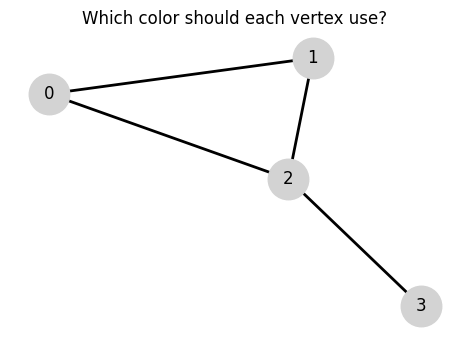

In [3]:
graph = nx.Graph([(0, 1), (1, 2), (0, 2), (2, 3)])
positions = nx.spring_layout(graph, seed=7)

plt.figure(figsize=(4.5, 3))
nx.draw(
    graph,
    pos=positions,
    with_labels=True,
    node_color="lightgray",
    node_size=850,
    width=2,
)
plt.title("Which color should each vertex use?")
plt.show()

頂点数を$N$、色数を$K$、辺の集合を$E$とします。
**決定変数**$x_{v,c}$は、頂点$v$に色$c$を割り当てた場合に1、それ以外の場合に0となる二値変数です。

次の定式化では、各頂点にちょうど1色を割り当てるという**制約**のもとで、衝突数を表す**目的関数**$f(x)$を最小化します。

$$
\begin{aligned}
\underset{x\in\{0,1\}^{N\times K}}{\operatorname{minimize}}
\quad & f(x)=\sum_{(u,v)\in E}\sum_{c=0}^{K-1}x_{u,c}x_{v,c}\\
\text{subject to}\quad & \sum_{c=0}^{K-1}x_{v,c}=1
\quad(v=0,\ldots,N-1).
\end{aligned}
$$

各頂点の変数のうち、ちょうど1つだけが1になる制約を**one-hot制約**と呼びます。
たとえば、$x_{v,1} = 1$は頂点$v$に色1を割り当てることを表します。
この制約を満たすと、各辺に対する項$\sum_c x_{u,c}x_{v,c}$は、両端が同じ色なら1、それ以外なら0になります。

制約を満たす割り当てを**実行可能解**と呼びます。その割り当てに対する目的関数の値が**目的値**です。
目的値が最小の実行可能解を**最適解**と呼び、その目的値を**最適値**と呼びます。
このモデルでは、衝突が残っていても、各頂点に1色ずつ割り当てられていれば実行可能です。
目的値が0の実行可能解では、どの辺も両端の色が異なり、正しく彩色できています。

### JijModelingで定式化を記述する

`N`、`K`、`E`は後からデータを与えるためのプレースホルダーです。
`x`は形状が `(N, K)` の二値変数の配列で、頂点と色の組ごとに1つの変数を持ちます。

目的関数では、内側の `sum()` で色ごとの項を足し、外側の `sum()` で辺ごとの項を足します。
`Constraint(..., domain=N)` で各頂点にone-hot制約を追加します。

In [4]:
problem = jm.Problem("Graph Coloring")


@problem.update
def _(problem: jm.DecoratedProblem):
    N = problem.Dim()
    K = problem.Dim()
    E = problem.Natural(ndim=2)
    x = problem.BinaryVar(shape=(N, K))
    # 目的関数では、両端が同じ色の辺を数えます。
    problem += E.rows().map(lambda edge: (x[edge[0], :] * x[edge[1], :]).sum()).sum()
    # 各頂点にちょうど1色を割り当てる制約を追加します。
    problem += problem.Constraint("one-color", lambda v: x[v, :].sum() == 1, domain=N)


problem

Problem(name="Graph Coloring", sense=MINIMIZE, objective=sum(E.rows().map(lambda (edge: Array[:; natural]): sum(x[edge[0], (:)] * x[edge[1], (:)]))), constraints={one-color: [Constraint(name="one-color", , lambda v: sum(x[v, (:)]) == 1, domain=set(N)),],})

## 2. モデルに入力データを与える

**インスタンス**は、具体的な入力データを与えた数理モデルです。
`problem.eval(instance_data)` は頂点数、色数、辺を代入し、共通データ形式であるOMMXの `Instance` を生成します。
この時点では、色の割り当て$x$はまだ決まっていません。

最適化問題を解くソフトウェアを**ソルバー**と呼びます。
この `instance` を使い、QAOA、OpenJij SA、SCIPで同じ問題を解きます。
出力に頂点4個、色3色、二値変数12個、one-hot制約4個が表示されることを確認します。

In [5]:
instance_data = {
    "N": graph.number_of_nodes(),
    "K": NUM_COLORS,
    "E": [list(edge) for edge in graph.edges()],
}
instance = problem.eval(instance_data)
print("vertices:", instance_data["N"])
print("colors:", NUM_COLORS)
print("binary variables:", len(instance.decision_variables))
print("one-hot constraints:", len(instance.constraints))
assert len(instance.decision_variables) == graph.number_of_nodes() * NUM_COLORS
assert len(instance.constraints) == graph.number_of_nodes()

vertices: 4
colors: 3
binary variables: 12
one-hot constraints: 4


## 3. 問題をQAOA回路に変換する

**QUBO**（制約なし二次二値最適化）では、明示的な制約を設けず、二値変数の二次式を最小化します。
`OMMXProblem.from_instance()` は制約違反へのペナルティを元の目的関数に加えてQUBOに変換します。次に `to_ising()` でイジングモデルに変換します。ここで使うQUBOは次の式です。

$$
F(x)=f(x)+A\sum_{v=0}^{N-1}\left(\sum_{c=0}^{K-1}x_{v,c}-1\right)^2.
$$

追加した項は、one-hot制約を満たすと0になり、違反すると正になります。
たとえば、すべての変数を0にすると$f(x)=0$ですが、どの頂点にも色を割り当てていないため、ペナルティが加わります。
**$A=|E|+1=5$**とします。
実行可能解では$F(x)=f(x)\leq |E|$となります。制約に違反する候補では$F(x)\geq A$となります。
このため、QUBOの最適解は元の制約も満たします。

$x=(1-z)/2$を代入し、二値変数をスピン変数$z\in\{+1,-1\}$に置き換えると、イジングモデルになります。
対応するコストハミルトニアンを使い、`QAOAExperiment(..., layers=1).compile(...)` で1層のQAOA回路を作ります。
このモデルでは補助変数が不要なので、量子ビット数は二値変数の数$NK=12$と等しくなります。

`normalize_by_abs_max()` はすべての係数を同じ正の定数で割って正規化します。エネルギーを最小にするビット列は変わりません。
`qm.qiskit.Aer()` でQiskit Aerシミュレーターを実行先に設定します。

In [6]:
penalty_weight = graph.number_of_edges() + 1
optimization_problem = OMMXProblem.from_instance(
    instance, uniform_penalty_weight=penalty_weight
)
spin_model = optimization_problem.model.to_ising().normalize_by_abs_max()

endpoint = qm.qiskit.Aer()
qaoa = QAOAExperiment(spin_model, layers=1).compile(to=endpoint.target)

print("penalty weight:", penalty_weight)
print("QAOA qubits:", spin_model.num_variables)
assert spin_model.num_variables == len(instance.decision_variables)

penalty weight: 5
QAOA qubits: 12


## 4. 回路のパラメータを調整する

ペナルティを含むエネルギーの期待値を下げるために、QAOA回路のパラメータを調整します。
1層の回路で調整するパラメータは$\gamma,\beta$の2つです。

`remove_final_measurements()` で期待値の計算に使う測定なしの回路を作ります。その回路をAerが扱えるゲートにトランスパイルします。
`energy()` は `params[0]` を$\gamma$、`params[1]` を$\beta$として回路に設定し、Qiskit Aerの `EstimatorV2` で期待値を計算します。
状態ベクトルから直接計算するため、ここではショットは不要です。

`minimize()` でパラメータを調整し、次の節で最後の測定から色の割り当てを得ます。

In [7]:
def cost_operator(model):
    """Express the normalized Ising cost as a Qiskit Pauli operator."""
    terms = [
        (
            "".join(factor.pauli.value for factor in word.factors),
            [factor.index for factor in word.factors],
            coefficient,
        )
        for word, coefficient in model.hamiltonian.terms
    ]
    return SparsePauliOp.from_sparse_list(
        terms + [("I", [0], model.hamiltonian.constant)],
        num_qubits=model.num_variables,
    )


state_circuit = load_circuit(qaoa.artifact).remove_final_measurements(inplace=False)
state_circuit = transpile(state_circuit, AerSimulator(), optimization_level=0)
hamiltonian = cost_operator(spin_model)
estimator = EstimatorV2(
    options={"backend_options": {"method": "statevector", "max_parallel_threads": 1}}
)


def energy(params, artifact, circuit, operator):
    invocation = qm.Invocation.create(
        parameters={"gammas": [params[0]], "betas": [params[1]]}
    )
    bound = bind_circuit(circuit, artifact, invocation)
    result = estimator.run([(bound, operator)], precision=0.0).result()
    return float(result[0].data.evs)


initial_params = np.random.default_rng(7).uniform(0.0, np.pi, 2)
optimized = minimize(
    energy,
    initial_params,
    args=(qaoa.artifact, state_circuit, hamiltonian),
    method="COBYLA",
    options={"maxiter": MAX_EVALS},
)
print("optimized parameters:", optimized.x)

optimized parameters: [3.82315702 2.00090284]


## 5. 測定結果から色の割り当てを復元する

最適化したパラメータで `FINAL_SHOTS` 回測定し、各候補を元のOMMXインスタンスの変数に対応付けます。
次に `OMMXProblem.evaluate()` でone-hot制約を満たしているかを確認し、元の目的値$f(x)$を計算します。
シミュレーターの乱数シードを変えると、測定結果も変わることがあります。

前の節で最小化したエネルギーの期待値には、ペナルティが含まれます。
**解を比較するときは、ペナルティを含まない元の目的値を使います。** 実行可能解の場合、この値は衝突数です。

`best_feasible_or_none()` は、得られた実行可能解のうち目的値が最も小さいものを選びます。
QAOAで得られた候補がすべて制約に違反することもあります。実行可能解が見つからない場合、この関数は `None` を返します。

In [8]:
def best_feasible_or_none(samples):
    if not samples.summary["feasible"].any():
        return None
    return samples.best_feasible


def feasible_shot_rate(evaluation):
    feasible = evaluation.feasible
    return (
        sum(
            count
            for sample_id, count in evaluation.occurrences.items()
            if feasible[sample_id]
        )
        / evaluation.total_occurrences
    )


final_sample = qm.run(
    qaoa.artifact,
    on=endpoint,
    shots=FINAL_SHOTS,
    seed=7,
    parameters={
        "gammas": [optimized.x[0]],
        "betas": [optimized.x[1]],
    },
).result
assert final_sample.shots == FINAL_SHOTS
qaoa_evaluation = optimization_problem.evaluate(
    optimization_problem.model.decode(final_sample)
)
qaoa_solution = best_feasible_or_none(qaoa_evaluation.sample_set)

if qaoa_solution is None:
    print("No one-hot-feasible sample. Try more shots or another seed.")
else:
    print("best conflicts:", qaoa_solution.objective)
    print("proper coloring:", np.isclose(qaoa_solution.objective, 0))

best conflicts: 0.0
proper coloring: True


### 色の割り当てを確認する

`extract_decision_variables("x")` で、頂点の番号と色の番号の組 `(vertex index, color index)` ごとに変数の値を取り出します。
選んだ解はone-hot制約を満たすため、値が1の変数から各頂点の色が分かります。

図の `v: c` は頂点の番号と色の番号を示します。衝突している辺は赤で表示され、その数はタイトルの `conflict(s)` で確認できます。

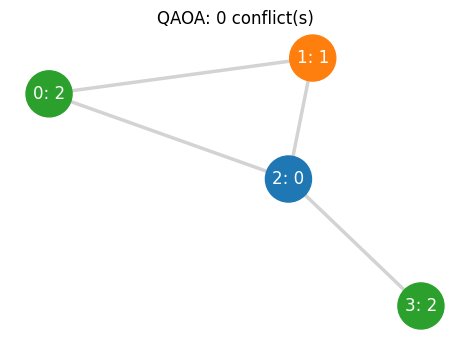

vertex -> color: {0: 2, 1: 1, 2: 0, 3: 2}


In [9]:
if qaoa_solution is not None:
    values = qaoa_solution.extract_decision_variables("x")
    assignment = {v: c for (v, c), value in values.items() if value > 0.5}
    conflicts = [(u, v) for u, v in graph.edges if assignment[u] == assignment[v]]
    assert np.isclose(qaoa_solution.objective, len(conflicts))
    palette = plt.get_cmap("tab10")
    plt.figure(figsize=(4.5, 3))
    nx.draw(
        graph,
        pos=positions,
        labels={v: f"{v}: {assignment[v]}" for v in graph.nodes},
        node_color=[palette(assignment[v]) for v in graph.nodes],
        edge_color=["tab:red" if e in conflicts else "lightgray" for e in graph.edges],
        width=2.5,
        node_size=1100,
        font_color="white",
    )
    plt.title(f"QAOA: {len(conflicts)} conflict(s)")
    plt.show()
    print("vertex -> color:", assignment)

## 6. 古典ソルバーと比較する

同じ `instance` をOMMXアダプターに渡し、各ソルバーが必要とする形式に変換します。
次の2つのソルバーでQAOAと同じ問題を解きます。

- **OpenJij SA**はシミュレーテッドアニーリングを実行します。QAOAと同じペナルティ係数を使い、試行回数を `SA_READS` に設定します。
- **SCIP**は元の目的関数と制約を扱います。SCIPが求めた最適値を比較の基準にします。

QAOAとSAでは、得られた実行可能解のうち目的値が最も小さいものを選びます。
その目的値をSCIPの最適値と比較し、選んだ解が最適かどうかを確認します。

In [10]:
openjij_samples = OMMXOpenJijSAAdapter.sample(
    instance,
    num_reads=SA_READS,
    uniform_penalty_weight=penalty_weight,
)
openjij_solution = best_feasible_or_none(openjij_samples)

scip_solution = OMMXPySCIPOptAdapter.solve(instance)
assert scip_solution.feasible and np.isclose(scip_solution.objective, 0)

元の問題の目的値を使い、結果を比較します。

| 列 | 意味 |
| --- | --- |
| `best` | 得られた実行可能解のうち最小の目的値 |
| `gap` | `best` からSCIPの最適値を引いた値 |
| `feasible_rate` | 得られた候補のうち実行可能なものの割合（0〜1） |

**`best=0` は衝突がないことを示し、`gap=0` は解が最適であることを示します。**
たとえば、最適値が1の問題で目的値が1の実行可能解が得られた場合、`best=1`、`gap=0` になります。
実行可能解が見つからない場合、`best` と `gap` は欠損値を表す `NaN` になります。SCIPは実行可能解を返すので、ここではその `feasible_rate` を1.0に設定します。

In [11]:
solutions = {
    "QAOA": qaoa_solution,
    "OpenJij SA": openjij_solution,
    "SCIP": scip_solution,
}
comparison = pd.DataFrame(
    [
        {"method": method, "best": np.nan if solution is None else solution.objective}
        for method, solution in solutions.items()
    ]
)
comparison["gap"] = comparison["best"] - scip_solution.objective
comparison["feasible_rate"] = [
    feasible_shot_rate(qaoa_evaluation),
    openjij_samples.summary["feasible"].mean(),
    1.0,
]
comparison

,method,best,gap,feasible_rate
0,QAOA,0.0,0.0,0.125977
1,OpenJij SA,0.0,0.0,1.000000
2,SCIP,0.0,0.0,1.000000


## 7. 問題のサイズを変えて比較する

最後に、頂点数を3、4、5、6と変えて、**最適値との差と実行時間**を比較します。
色数は `NUM_COLORS` に固定します。3色の場合、各問題で使う量子ビット数は順に9、12、15、18です。

各サイズでは頂点の組を確率0.5で辺で結び、ランダムグラフを生成します。さらに、グラフが連結になるよう辺 `(0, 1), (1, 2), ...` を加えます。
グラフの生成に使う乱数シードを固定し、3つの手法に同じOMMXインスタンスを渡します。
与えられた色数で正しく彩色できない場合もあるため、各サイズの最適値はSCIPで求めます。

QAOAとSAはいずれもペナルティ係数$A=|E|+1$を使います。
QAOAは1層です。最後の測定回数と評価回数の上限、SAの試行回数には、冒頭で定義した共通の定数を使います。

In [12]:
problem_sizes = [3] if docs_test_mode else [3, 4, 5, 6]

第3節から第5節までのQAOAの手順を `solve_with_qaoa()` にまとめます。
この関数は選んだ解と実行可能な候補の割合を返します。実行可能解が見つからないとき、解は `None` になります。

次のループでは、各ソルバーで処理する前後に時刻を記録し、経過時間を求めます。

In [13]:
def solve_with_qaoa(instance, penalty_weight, seed):
    problem = OMMXProblem.from_instance(instance, uniform_penalty_weight=penalty_weight)
    spin_model = problem.model.to_ising().normalize_by_abs_max()
    qaoa = QAOAExperiment(spin_model, layers=1).compile(to=endpoint.target)
    state_circuit = load_circuit(qaoa.artifact).remove_final_measurements(inplace=False)
    state_circuit = transpile(state_circuit, AerSimulator(), optimization_level=0)
    hamiltonian = cost_operator(spin_model)

    initial = np.random.default_rng(seed).uniform(0.0, np.pi, 2)
    optimized = minimize(
        energy,
        initial,
        args=(qaoa.artifact, state_circuit, hamiltonian),
        method="COBYLA",
        options={"maxiter": MAX_EVALS},
    )
    sample = qm.run(
        qaoa.artifact,
        on=endpoint,
        shots=FINAL_SHOTS,
        seed=seed,
        parameters={
            "gammas": [optimized.x[0]],
            "betas": [optimized.x[1]],
        },
    ).result
    assert sample.shots == FINAL_SHOTS
    evaluation = problem.evaluate(problem.model.decode(sample))
    return best_feasible_or_none(evaluation.sample_set), feasible_shot_rate(evaluation)

In [14]:
benchmark_rows = []
for num_vertices in problem_sizes:
    benchmark_graph = nx.gnp_random_graph(num_vertices, p=0.5, seed=1000 + num_vertices)
    benchmark_graph.add_edges_from((v, v + 1) for v in range(num_vertices - 1))
    benchmark_instance = problem.eval(
        {
            "N": num_vertices,
            "K": NUM_COLORS,
            "E": [list(edge) for edge in benchmark_graph.edges()],
        }
    )
    penalty = benchmark_graph.number_of_edges() + 1
    qubits = num_vertices * NUM_COLORS
    print(
        f"Solving N={num_vertices}, edges={benchmark_graph.number_of_edges()}, qubits={qubits}"
    )

    started = time.perf_counter()
    scip_best = OMMXPySCIPOptAdapter.solve(benchmark_instance)
    scip_elapsed = time.perf_counter() - started
    reference = scip_best.objective

    started = time.perf_counter()
    sa_samples = OMMXOpenJijSAAdapter.sample(
        benchmark_instance,
        num_reads=SA_READS,
        uniform_penalty_weight=penalty,
    )
    sa_best = best_feasible_or_none(sa_samples)
    sa_rate = sa_samples.summary["feasible"].mean()
    sa_elapsed = time.perf_counter() - started

    started = time.perf_counter()
    qaoa_best, qaoa_rate = solve_with_qaoa(
        benchmark_instance, penalty, seed=7 + num_vertices
    )
    qaoa_elapsed = time.perf_counter() - started
    for method, solution, elapsed, feasible_rate in [
        ("QAOA", qaoa_best, qaoa_elapsed, qaoa_rate),
        ("OpenJij SA", sa_best, sa_elapsed, sa_rate),
        ("SCIP", scip_best, scip_elapsed, 1.0),
    ]:
        best = np.nan if solution is None else solution.objective
        benchmark_rows.append(
            {
                "vertices": num_vertices,
                "qubits": qubits,
                "edges": benchmark_graph.number_of_edges(),
                "method": method,
                "best": best,
                "gap": best - reference,
                "feasible_rate": feasible_rate,
                "seconds": elapsed,
            }
        )

Solving N=3, edges=3, qubits=9


Solving N=4, edges=3, qubits=12


Solving N=5, edges=6, qubits=15


Solving N=6, edges=12, qubits=18


`best`、`gap`、`feasible_rate` は第6節と同じ指標です。次の列で問題のサイズと実行時間も示します。

| 列 | 意味 |
| --- | --- |
| `vertices` | 頂点数 |
| `qubits` | QAOAで使う量子ビット数 |
| `edges` | 辺の数 |
| `seconds` | 問題の変換から求解、解の評価と選択までの経過時間（秒） |

計測にはOMMXインスタンスの作成と作図は含めません。
実行可能解が見つからない場合、`best` と `gap` は `NaN` になり、次のグラフではそのサイズの `gap` の点を表示しません。

In [15]:
benchmark = pd.DataFrame(benchmark_rows)
assert len(benchmark) == 3 * len(problem_sizes)
assert (benchmark["gap"].dropna() >= -1e-8).all()
benchmark

,vertices,qubits,edges,method,best,gap,feasible_rate,seconds
0,3,9,3,QAOA,0.0,0.0,0.285156,0.337486
1,3,9,3,OpenJij SA,0.0,0.0,1.000000,0.045100
2,3,9,3,SCIP,0.0,0.0,1.000000,0.002307
3,4,12,3,QAOA,0.0,0.0,0.211426,0.489470
4,4,12,3,OpenJij SA,0.0,0.0,1.000000,0.053519
5,4,12,3,SCIP,0.0,0.0,1.000000,0.002351
6,5,15,6,QAOA,0.0,0.0,0.208008,0.953991
7,5,15,6,OpenJij SA,0.0,0.0,1.000000,0.060744
8,5,15,6,SCIP,0.0,0.0,1.000000,0.003644
9,6,18,12,QAOA,1.0,0.0,0.008301,3.526588


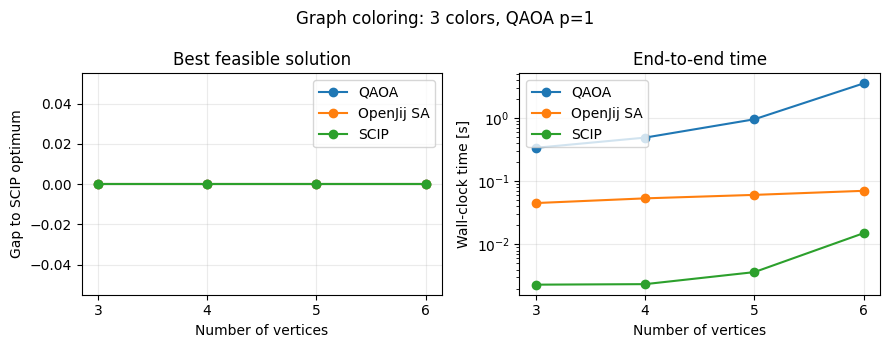

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for method, rows in benchmark.groupby("method", sort=False):
    axes[0].plot(rows["vertices"], rows["gap"], "o-", label=method)
    axes[1].plot(rows["vertices"], rows["seconds"], "o-", label=method)

axes[0].set(title="Best feasible solution", ylabel="Gap to SCIP optimum")
axes[1].set(title="End-to-end time", ylabel="Wall-clock time [s]", yscale="log")
for axis in axes:
    axis.set_xlabel("Number of vertices")
    axis.set_xticks(problem_sizes)
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(f"Graph coloring: {NUM_COLORS} colors, QAOA p=1")
plt.tight_layout()
plt.show()

左のグラフは最適値との差を比較します。右のグラフは実行時間を比較し、縦軸は対数目盛です。
すべての手法が最適値に達したサイズでは、左のグラフの線が0で重なります。

:::{note}
**この比較について**

この小規模な例の目的は、処理の流れを学ぶことです。QAOA回路のパラメータ$\gamma,\beta$は最適化していますが、性能比較のために層数、評価回数の上限、SAの設定を十分に調整したわけではありません。

各サイズで使うグラフが1つで、実行も1回だけなので、どの手法の性能が一般に高いかはこの結果から判断できません。詳しく比較するには、複数のグラフと乱数シードが必要です。

QAOAは古典シミュレーターで実行しているため、ここでの計測値は量子ハードウェア上の実行時間を表しません。
:::

## まとめ

JijModelingで問題を定式化し、OMMXインスタンスからQAOA回路を作成して、得られた解を元の問題に対して評価しました。
同じインスタンスを古典ソルバーに渡すことで、**実行可能解の目的値と実行時間を同じ基準で比較**できました。

APIの詳細は、[JijModelingのモデリングガイド](https://jij-inc-jijmodeling-tutorials-en.readthedocs-hosted.com/en/v2.6.0/basics/modeling.html)と[QamomileのQAOA実験リファレンス](../api/optimization/qaoa.md)を参照してください。